In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/Customer_Churn_Simple_18Cols.csv')

In [3]:
df.head()

,CustomerID,Age,Gender,Region,TenureMonths,ContractType,PaymentMethod,MonthlyCharges,TotalCharges,NumberOfServices,SupportCallsMade,PaymentDelayDays,UsageHoursPerMonth,SatisfactionScore,LastLoginDaysAgo,HasPromotionalDiscount,AutoRenewal,Churn
0,1,61,Female,East,9,Monthly,Debit Card,72.43,655.96,1,1,3,45,7,83,0,0,0
1,2,33,Male,South,36,Monthly,Credit Card,26.78,984.37,5,3,0,46,10,47,0,0,0
2,3,40,Male,South,15,Monthly,Debit Card,64.34,966.00,5,2,0,0,5,71,0,1,0
3,4,45,Female,West,16,Monthly,Net Banking,56.45,887.77,2,1,0,70,5,7,0,0,0
4,5,29,Female,Central,37,Yearly,Credit Card,19.10,684.92,4,1,0,28,9,29,1,1,0


In [4]:
df.shape

(300000, 18)

In [5]:
df.isnull().sum()

,0
CustomerID,0
Age,0
Gender,0
Region,0
TenureMonths,0
ContractType,0
PaymentMethod,0
MonthlyCharges,0
TotalCharges,0
NumberOfServices,0


In [6]:
df['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [7]:
df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})

In [8]:
df['Region'].unique()

array(['East', 'South', 'West', 'Central', 'North'], dtype=object)

In [9]:
df['Region'] = df['Region'].map({'East': 0, 'South': 1, 'West': 2, 'Central': 3, 'North': 4})

In [10]:
df['ContractType'].unique()

array(['Monthly', 'Yearly', 'Two-Year'], dtype=object)

In [11]:
df['ContractType'] = df['ContractType'].map({'Monthly': 0, 'Yearly': 1, 'Two-Year': 2})

In [12]:
df['PaymentMethod'].unique()

array(['Debit Card', 'Credit Card', 'Net Banking', 'UPI', 'Cash'],
      dtype=object)

In [13]:
df['PaymentMethod'] = df['PaymentMethod'].map({'Debit Card': 0, 'Credit Card': 1, 'Net Banking': 2, 'UPI': 3, 'Cash': 4})

In [14]:
df.head()

,CustomerID,Age,Gender,Region,TenureMonths,ContractType,PaymentMethod,MonthlyCharges,TotalCharges,NumberOfServices,SupportCallsMade,PaymentDelayDays,UsageHoursPerMonth,SatisfactionScore,LastLoginDaysAgo,HasPromotionalDiscount,AutoRenewal,Churn
0,1,61,0,0,9,0,0,72.43,655.96,1,1,3,45,7,83,0,0,0
1,2,33,1,1,36,0,1,26.78,984.37,5,3,0,46,10,47,0,0,0
2,3,40,1,1,15,0,0,64.34,966.00,5,2,0,0,5,71,0,1,0
3,4,45,0,2,16,0,2,56.45,887.77,2,1,0,70,5,7,0,0,0
4,5,29,0,3,37,1,1,19.10,684.92,4,1,0,28,9,29,1,1,0


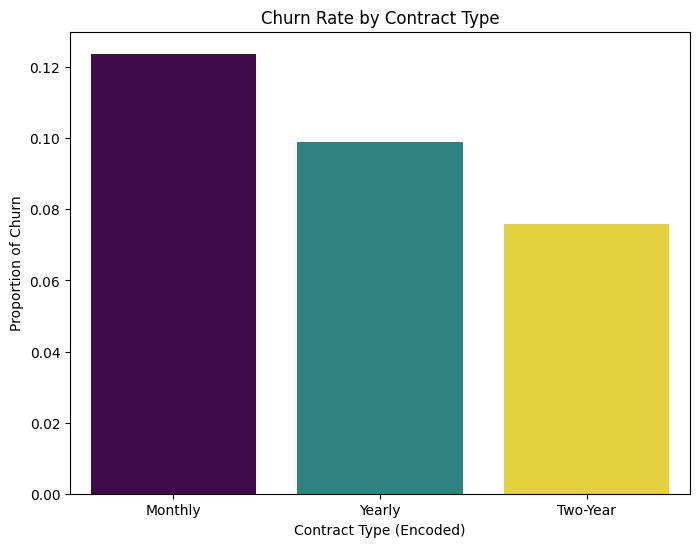

In [29]:
plt.figure(figsize=(8, 6))
sns.barplot(data=contract_churn, x='ContractType', y='Churn', hue='ContractType', palette='viridis', legend=False)
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type (Encoded)')
plt.ylabel('Proportion of Churn')
plt.xticks(ticks=range(len(contract_map)), labels=list(contract_map.keys()))
plt.show()

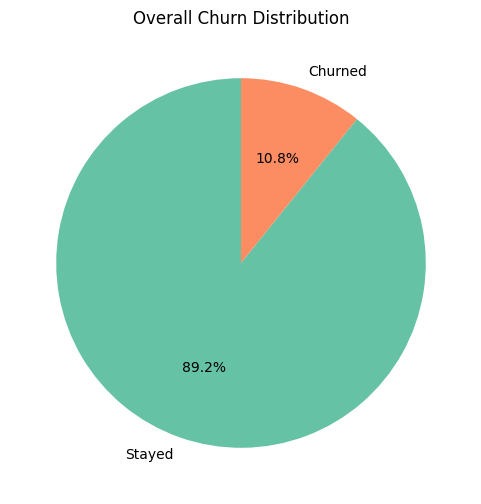

In [32]:
churn_counts = df['Churn'].value_counts()
churn_labels = ['Stayed' if idx == 0 else 'Churned' for idx in churn_counts.index]

plt.figure(figsize=(6, 6))
plt.pie(churn_counts, labels=churn_labels, autopct='%1.1f%%', startangle=90, colors=['#66c2a5', '#fc8d62'])
plt.title('Overall Churn Distribution')
plt.ylabel('') # Hide the default 'y' label for pie charts
plt.show()

In [16]:
x = df.drop(['CustomerID', 'Churn'],axis =1)
y = df['Churn']

In [17]:
from sklearn.model_selection  import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

In [18]:
x = pd.get_dummies(x,drop_first=True)

In [19]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state = 42)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [20]:
model = XGBClassifier()
model.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [21]:
model.score(x_train, y_train)

0.8942190476190476

In [22]:
model.score(x_test, y_test)

0.8922

In [23]:
df.head()

,CustomerID,Age,Gender,Region,TenureMonths,ContractType,PaymentMethod,MonthlyCharges,TotalCharges,NumberOfServices,SupportCallsMade,PaymentDelayDays,UsageHoursPerMonth,SatisfactionScore,LastLoginDaysAgo,HasPromotionalDiscount,AutoRenewal,Churn
0,1,61,0,0,9,0,0,72.43,655.96,1,1,3,45,7,83,0,0,0
1,2,33,1,1,36,0,1,26.78,984.37,5,3,0,46,10,47,0,0,0
2,3,40,1,1,15,0,0,64.34,966.00,5,2,0,0,5,71,0,1,0
3,4,45,0,2,16,0,2,56.45,887.77,2,1,0,70,5,7,0,0,0
4,5,29,0,3,37,1,1,19.10,684.92,4,1,0,28,9,29,1,1,0


In [50]:
importances = pd.Series(model.feature_importances_, index=x.columns).sort_values(ascending=False)
top_features = importances.head(6).index.tolist()

extra_features = ['AutoRenewal', 'Age', 'Gender', 'HasPromotionalDiscount']
display_features = top_features + [f for f in extra_features if f not in top_features]

default_values = {}
for col in x.columns:
    if col in df.columns:
        default_values[col] = df[col].mean() if df[col].dtype in ['int64','float64'] else df[col].mode()[0]
    else:
        default_values[col] = 0

gender_map = {'Female': 0, 'Male': 1}
region_map = {'East': 0, 'South': 1, 'West': 2, 'Central': 3, 'North': 4}
contract_map = {'Monthly': 0, 'Yearly': 1, 'Two-Year': 2}
payment_map = {'Debit Card': 0, 'Credit Card': 1, 'Net Banking': 2, 'UPI': 3, 'Cash': 4}

def predict_churn_simple(**kwargs):
    customer = default_values.copy()
    customer.update(kwargs)

    if isinstance(customer.get('Gender'), str):
        customer['Gender'] = gender_map[customer['Gender']]
    if isinstance(customer.get('Region'), str):
        customer['Region'] = region_map[customer['Region']]
    if isinstance(customer.get('ContractType'), str):
        customer['ContractType'] = contract_map[customer['ContractType']]
    if isinstance(customer.get('PaymentMethod'), str):
        customer['PaymentMethod'] = payment_map[customer['PaymentMethod']]

    df_input = pd.DataFrame([customer])[x.columns]
    scaled_input = scaler.transform(df_input)

    prediction = model.predict(scaled_input)[0]
    churn_probability = model.predict_proba(scaled_input)[0][1]

    print("--- Prediction Result ---")
    if prediction == 1:
        print(f"⚠️  ALERT: This customer is likely to CHURN ({churn_probability:.1%} risk)")
    else:
        print(f"✅ SAFE: This customer is likely to STAY ({churn_probability:.1%} risk)")

    print("\nKey factors considered:")
    for feat in display_features:
        print(f"  • {feat}: {customer.get(feat, 'N/A')}")

    return prediction, churn_probability


predict_churn_simple(
    Age =55,
    Gender = 'Female',
    TenureMonths=35,
    ContractType='Monthly',
    SupportCallsMade=13,
    LastLoginDaysAgo=90,
    PaymentDelayDays=90,
    SatisfactionScore=4,
    AutoRenewal=0,
    HasPromotionalDiscount=0
)

--- Prediction Result ---
⚠️  ALERT: This customer is likely to CHURN (85.4% risk)

Key factors considered:
  • ContractType: 0
  • SatisfactionScore: 4
  • TenureMonths: 35
  • LastLoginDaysAgo: 90
  • AutoRenewal: 0
  • HasPromotionalDiscount: 0
  • Age: 55
  • Gender: 0


(np.int64(1), np.float32(0.85401464))

In [25]:
importances = pd.Series(model.feature_importances_, index=x.columns).sort_values(ascending=False)
print(importances)

ContractType              0.125782
SatisfactionScore         0.109451
TenureMonths              0.103850
LastLoginDaysAgo          0.098356
AutoRenewal               0.098067
HasPromotionalDiscount    0.076412
PaymentDelayDays          0.060757
UsageHoursPerMonth        0.049124
SupportCallsMade          0.042886
TotalCharges              0.037645
MonthlyCharges            0.033999
Gender                    0.033787
PaymentMethod             0.033528
Region                    0.033148
Age                       0.032401
NumberOfServices          0.030807
dtype: float32


In [26]:
print("Churn distribution:")
print(df['Churn'].value_counts())
print(f"Percentage of churners: {df['Churn'].mean()*100:.2f}%")

Churn distribution:
Churn
0    267628
1     32372
Name: count, dtype: int64
Percentage of churners: 10.79%


In [52]:
import joblib
joblib.dump(model, '/content/Customer_Churn_Simple_18Cols.csv.joblib')

['/content/Customer_Churn_Simple_18Cols.csv.joblib']